<a href="https://colab.research.google.com/github/clin0603/csci3052u-group-project/blob/main/milestone3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3: Nevada mortgage approval baseline
**Team Remedial Finance**

Train: 2007. Validation: 2008. Final test: 2009. The primary data are the randomized CSVs already used in the team repository.

In [ ]:
#imports
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Data Source


In [ ]:
# Create folder in Colab
!mkdir -p Random_Mortgage_Data
# Download randomized datasets into the folder
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data07.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data07.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data08.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data08.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data09.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data09.csv

# Create folder in Colab
!mkdir -p Cut_Mortgage_Data
# Download cut datasets into the folder
!wget -q -O Cut_Mortgage_Data/Random_Mortage_Data07.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data07.csv
!wget -q -O Cut_Mortgage_Data/Random_Mortage_Data08.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data08.csv
!wget -q -O Cut_Mortgage_Data/Random_Mortage_Data09.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data09.csv

In [ ]:
file_paths = [
    "Random_Mortgage_Data/Random_Mortgage_Data07.csv",
    "Random_Mortgage_Data/Random_Mortgage_Data08.csv",
    "Random_Mortgage_Data/Random_Mortgage_Data09.csv"
]

df = pd.concat(
    [pd.read_csv(file, low_memory=False) for file in file_paths],
    ignore_index=True
)

print("Dataset shape:", df.shape)

Dataset shape: (120000, 78)


In [ ]:
def verify_data():
    """Verify that data folders and files exist in the root directory."""
    rand_files = [
        "Random_Mortgage_Data/Random_Mortgage_Data07.csv",
        "Random_Mortgage_Data/Random_Mortgage_Data08.csv",
        "Random_Mortgage_Data/Random_Mortgage_Data09.csv"
    ]
    # Handle potential filename typo (Cut_Mortage vs Cut_Mortgage)
    cut_dir = Path("Cut_Mortgage_Data") if Path("Cut_Mortgage_Data").exists() else Path("Cut_Mortage_Data")

    for f in rand_files:
        if not Path(f).exists():
            raise FileNotFoundError(f"Missing required file: {f}")
    print("Data verification successful: All mortgage datasets found.")

verify_data()

Data verification successful: All mortgage datasets found.


## 2. Working pipeline and baselines
Actions 1 and 2 map to approved (1); action 3 maps to denied (0); other outcomes are excluded. Only loan amount, income, loan type and loan purpose enter the model. Numeric medians, missing indicators, scaling and one-hot encoding are fitted on 2007 only.

Majority classifier: always predicts the 2007 majority class. Course baseline: Euclidean kNN, uniform weights. Select k from 5, 15, 31, 61, 101 using 2008 ROC-AUC; use smaller k to break exact ties. Freeze k before testing 2009; do not refit on 2008.

In [ ]:
def run(mode="random"):
    if mode == "random":
        folder = Path("Random_Mortgage_Data")
    else:
        folder = Path("Cut_Mortgage_Data")

    train_files = list(folder.glob("*07.csv"))
    val_files = list(folder.glob("*08.csv"))
    test_files = list(folder.glob("*09.csv"))

    if not train_files or not val_files or not test_files:
        raise FileNotFoundError(
            f"Could not find required 07, 08, or 09 CSV files inside directory: {folder}"
        )

    df_train = pd.read_csv(train_files[0], low_memory=False)
    df_val = pd.read_csv(val_files[0], low_memory=False)
    df_test = pd.read_csv(test_files[0], low_memory=False)

    results_dir = Path(f"results/{mode}")
    results_dir.mkdir(parents=True, exist_ok=True)

    #Save data audit CSV
    audit_data = {
        "split": ["2007_train", "2008_val", "2009_test"],
        "rows": [len(df_train), len(df_val), len(df_test)],
    }
    pd.DataFrame(audit_data).to_csv(results_dir / "data_audit.csv", index=False)

    #Target and Feature Setup
    TARGET_COL = "action_taken"
    FEATURES = [
        "loan_amount_000s",
        "applicant_income_000s",
        "loan_type",
        "loan_purpose",
    ]
    NUMERIC_FEATURES = ["loan_amount_000s", "applicant_income_000s"]
    CATEGORICAL_FEATURES = ["loan_type", "loan_purpose"]

    def prep_target(df):
        # Actions 1 & 2 = Approved (1), Action 3 = Denied (0)
        df_filtered = df[df[TARGET_COL].isin([1, 2, 3])].copy()
        df_filtered["target"] = df_filtered[TARGET_COL].apply(
            lambda x: 1 if x in [1, 2] else 0
        )
        return df_filtered

    df_train = prep_target(df_train)
    df_val = prep_target(df_val)
    df_test = prep_target(df_test)

    X_train, y_train = df_train[FEATURES], df_train["target"]
    X_val, y_val = df_val[FEATURES], df_val["target"]
    X_test, y_test = df_test[FEATURES], df_test["target"]

    #Train-only Pipeline
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, NUMERIC_FEATURES),
            ("cat", categorical_transformer, CATEGORICAL_FEATURES),
        ]
    )

    # Fit preprocessing on 2007
    X_train_prep = preprocessor.fit_transform(X_train)
    X_val_prep = preprocessor.transform(X_val)
    X_test_prep = preprocessor.transform(X_test)

    #Validation Search for k
    k_values = [5, 15, 31, 61, 101]
    best_k = k_values[0]
    best_auc = -1
    val_search_results = {"k": [], "roc_auc": []}

    for k in k_values:
        knn = KNeighborsClassifier(
            n_neighbors=k, weights="uniform", metric="euclidean"
        )
        knn.fit(X_train_prep, y_train)
        y_val_probs = knn.predict_proba(X_val_prep)[:, 1]
        auc = roc_auc_score(y_val, y_val_probs)

        val_search_results["k"].append(k)
        val_search_results["roc_auc"].append(auc)

        if auc > best_auc:
            best_auc = auc
            best_k = k

    pd.DataFrame(val_search_results).to_csv(
        results_dir / "validation_search.csv", index=False
    )

    #Final Test Predictions on 2009
    majority_class = y_train.mode()[0]
    y_test_pred_base = [majority_class] * len(y_test)
    y_test_probs_base = [1.0 if majority_class == 1 else 0.0] * len(y_test)

    final_knn = KNeighborsClassifier(
        n_neighbors=best_k, weights="uniform", metric="euclidean"
    )
    final_knn.fit(X_train_prep, y_train)
    y_test_pred_knn = final_knn.predict(X_test_prep)
    y_test_probs_knn = final_knn.predict_proba(X_test_prep)[:, 1]

    #Generate Plot
    plt.figure(figsize=(6, 5))
    plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.50)")
    RocCurveDisplay.from_predictions(
        y_test,
        y_test_probs_knn,
        name=f"kNN Model (k={best_k})",
        ax=plt.gca(),
    )
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Test ROC Curve ({mode.capitalize()} Data)")
    plt.legend(loc="lower right")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.savefig(results_dir / "test_roc.png", bbox_inches="tight")
    plt.close()

    #Helper for Metrics
    def get_metrics(y_true, y_pred, y_probs, model_name):
        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=[0], zero_division=0
        )

        return {
            "split": "test",
            "model": model_name,
            "auc": roc_auc_score(y_true, y_probs),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "denial_precision": precision[0],
            "denial_recall": recall[0],
            "denial_f1": f1[0],
            "denied_as_denied": tn,
            "denied_as_approved": fp,
            "approved_as_denied": fn,
            "approved_as_approved": tp,
        }

    results = pd.DataFrame(
        [
            get_metrics(
                y_test,
                y_test_pred_base,
                y_test_probs_base,
                "Majority Baseline",
            ),
            get_metrics(
                y_test, y_test_pred_knn, y_test_probs_knn, f"kNN (k={best_k})"
            ),
        ]
    )

    return results

In [ ]:
primary = run('random')
display(pd.read_csv('results/random/data_audit.csv'))
display(pd.read_csv('results/random/validation_search.csv'))
display(primary.round(4))

,split,rows
0,2007_train,40000
1,2008_val,40000
2,2009_test,40000


,k,roc_auc
0,5,0.615435
1,15,0.658390
2,31,0.676919
3,61,0.690427
4,101,0.695471


,split,model,auc,accuracy,balanced_accuracy,denial_precision,denial_recall,denial_f1,denied_as_denied,denied_as_approved,approved_as_denied,approved_as_approved
0,test,Majority Baseline,0.5000,0.7429,0.5000,0.0000,0.0000,0.0000,0,6291,0,18179
1,test,kNN (k=101),0.6413,0.7472,0.5412,0.5387,0.1172,0.1925,737,5554,631,17548


## 3. Primary metric and error analysis
Evaluating mortgage models requires looking beyond raw accuracy, which can be misleading due to class imbalance. Because most applications are approved, a naive model can achieve a high accuracy score by approving every applicant, while completely failing to identify rejections. To get a complete performance picture, we use ROC-AUC to measure how effectively the model ranks approval probabilities approval being 1. We also track Denial Precision, Recall, and F1 to evaluate how reliably the model flags rejected loans denial being 0. Finally, raw confusion matrix counts expose exact errors for both outcomes, ensuring no class is hidden behind summary averages.

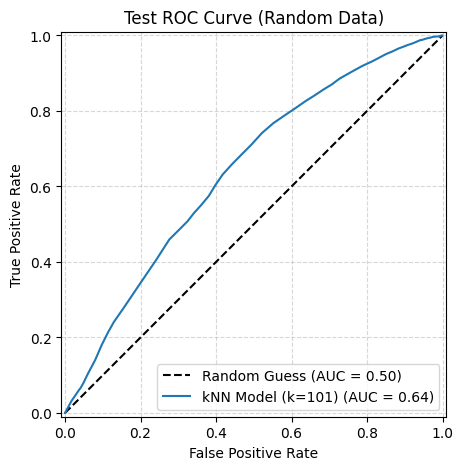

In [ ]:
roc_path = Path("results/random/test_roc.png")

if roc_path.exists():
    display(Image(filename=str(roc_path)))

## 4. Sensitivity Analysis
Using an independent validation search for $k$ on an alternative sample dataset, this comparison shows that metric shifts across years stem from changing sample sizes and selection methods, not just the financial crisis.

In [ ]:
sensitivity = run('cut')
display(pd.read_csv('results/cut/data_audit.csv'))
display(sensitivity[['split','model','auc','accuracy','denial_recall','denial_f1']].round(4))

,split,rows
0,2007_train,40000
1,2008_val,40000
2,2009_test,40000


,split,model,auc,accuracy,denial_recall,denial_f1
0,test,Majority Baseline,0.5000,0.7429,0.0000,0.0000
1,test,kNN (k=101),0.6413,0.7472,0.1172,0.1925


## 5. Other Requirements
Requirements baseline table; discrepancy analysis; start/stop/continue plan. will be expanded upon in the Milestone 3 Memo
https://docs.google.com/document/d/1CKFxWwoUzHLAO7YfzvwcpzszBwGWZ4mFXXErzA30hxc/edit?usp=sharing